# IE 7615 — Generative Project: Milestone 1 (V3.1)
**Pixel Art Text-to-Image Generation with Stable Diffusion 1.5**  
**Study Group 6:** Bingyan Zhu, Muhan Li, Ruoxi Chen

## Task 1. Environment Setup

In [ ]:

%pip -q uninstall -y gradio gradio-client

%pip -q install "diffusers>=0.33,<1" "transformers>=4.45,<5" "accelerate>=1,<2" "safetensors>=0.4" "Pillow>=10" matplotlib


In [ ]:
import csv
import json
import random
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

import torch
import diffusers
import transformers
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU in Colab Runtime settings.")
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Diffusers: 0.39.0
Transformers: 4.57.6
CUDA available: True
GPU: NVIDIA L4


## Task 2. Mount Drive and Set Paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project")
ZIP_PATH = PROJECT_DIR / "merged_images_512.zip"
METADATA_PATH = PROJECT_DIR / "metadata.jsonl"

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Missing archive: {ZIP_PATH}")
if not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Missing metadata: {METADATA_PATH}")

LOCAL_DIR = Path("/content/IE7615_P2_M1_V3_1")
LOCAL_ZIP = LOCAL_DIR / ZIP_PATH.name
IMAGE_DIR = LOCAL_DIR / "merged_images_512"
EXTRACT_MARKER = LOCAL_DIR / ".images_extracted"
RESULT_DIR = PROJECT_DIR / "results" / "milestone1_v3_1"
BASELINE_DIR = RESULT_DIR / "baseline"

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR)
print("Images archive:", ZIP_PATH.name)
print("Metadata:", METADATA_PATH.name)
print("Results:", RESULT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project
Images archive: merged_images_512.zip
Metadata: metadata.jsonl
Results: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/milestone1_v3_1


## Task 3. Extract Dataset

In [ ]:

from pathlib import Path, PurePosixPath
from collections import Counter
import shutil
import zipfile

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "IE 7615 深度学习/P2 Generative Project"
)

ZIP_PATH = PROJECT_DIR / "merged_images_512.zip"
METADATA_PATH = PROJECT_DIR / "metadata.jsonl"

LOCAL_ROOT = Path("/content/IE7615_P2_M1_V3_1")
LOCAL_ZIP = LOCAL_ROOT / ZIP_PATH.name
EXTRACT_DIR = LOCAL_ROOT / "dataset"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(METADATA_PATH)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

if not LOCAL_ZIP.exists():
    print("Copying ZIP to local storage...")
    shutil.copy2(ZIP_PATH, LOCAL_ZIP)

with zipfile.ZipFile(LOCAL_ZIP) as zf:
    png_members = [
        name for name in zf.namelist()
        if name.lower().endswith(".png")
    ]

    if not png_members:
        raise ValueError("No PNG images found in ZIP.")

    folder_counts = Counter(
        str(PurePosixPath(name).parent)
        for name in png_members
    )

    image_folder = folder_counts.most_common(1)[0][0]

    if not (EXTRACT_DIR / ".complete").exists():
        print("Extracting images...")
        zf.extractall(EXTRACT_DIR)
        (EXTRACT_DIR / ".complete").touch()

IMAGE_DIR = EXTRACT_DIR / image_folder

image_count = sum(1 for _ in IMAGE_DIR.glob("*.png"))

if image_count == 0:
    raise FileNotFoundError(
        f"No PNG images found in {IMAGE_DIR}"
    )

print(f"Image directory: {IMAGE_DIR}")
print(f"Images loaded: {image_count}")
print(f"Metadata: {METADATA_PATH}")
print("T3 complete.")


Copying ZIP to local storage...
Extracting images...
Image directory: /content/IE7615_P2_M1_V3_1/dataset
Images loaded: 5219
Metadata: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/metadata.jsonl
T3 complete.


## Task 4. Load Image–Caption Metadata

In [ ]:
with open(METADATA_PATH, "r", encoding="utf-8-sig") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("All metadata pairs:", len(records))
print("All image files:", image_count)
print("Metadata example:", records[0] if records else None)

family_counts = Counter(r["file_name"].split("_")[0] for r in records)
FAMILY_NAMES = {
    "01": "Animals",
    "04": "Plants and Fungi",
    "05": "Food and Drink",
    "16": "Nature and Landscapes",
}
for prefix, count in sorted(family_counts.items()):
    print(f"{prefix} {FAMILY_NAMES.get(prefix, 'Other')}: {count}")

summary = {
    "dataset": "unstonio/pixelgpt-24x24-20k (selected four families)",
    "source_archive": ZIP_PATH.name,
    "metadata": METADATA_PATH.name,
    "pairs_used": len(records),
    "png_count": image_count,
    "families": dict(sorted(family_counts.items())),
    "preprocessing": "Integer Nearest + Padding, 24x24 -> 504x504 -> 512x512 (performed locally)",
    "removed_or_sampled_records": 0,
    "split": "merged, not resplit yet",
}
with open(RESULT_DIR / "dataset_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Saved summary:", RESULT_DIR / "dataset_summary.json")

All metadata pairs: 5219
All image files: 5219
Metadata example: {'file_name': '01_00001.png', 'text': 'green frog ear drum large'}
01 Animals: 2202
04 Plants and Fungi: 1204
05 Food and Drink: 950
16 Nature and Landscapes: 863
Saved summary: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/milestone1_v3_1/dataset_summary.json


## Task 5. Select Five Reference Samples

1. 01_00457.png | pixel art of cutout bird in flight frame
2. 04_00052.png | pixel art of tiny cactus garden with flowers
3. 05_00760.png | pixel art of hot fudge cascade
4. 16_00282.png | pixel art of melting snow fleeting
5. 05_00251.png | pixel art of Hydras brew


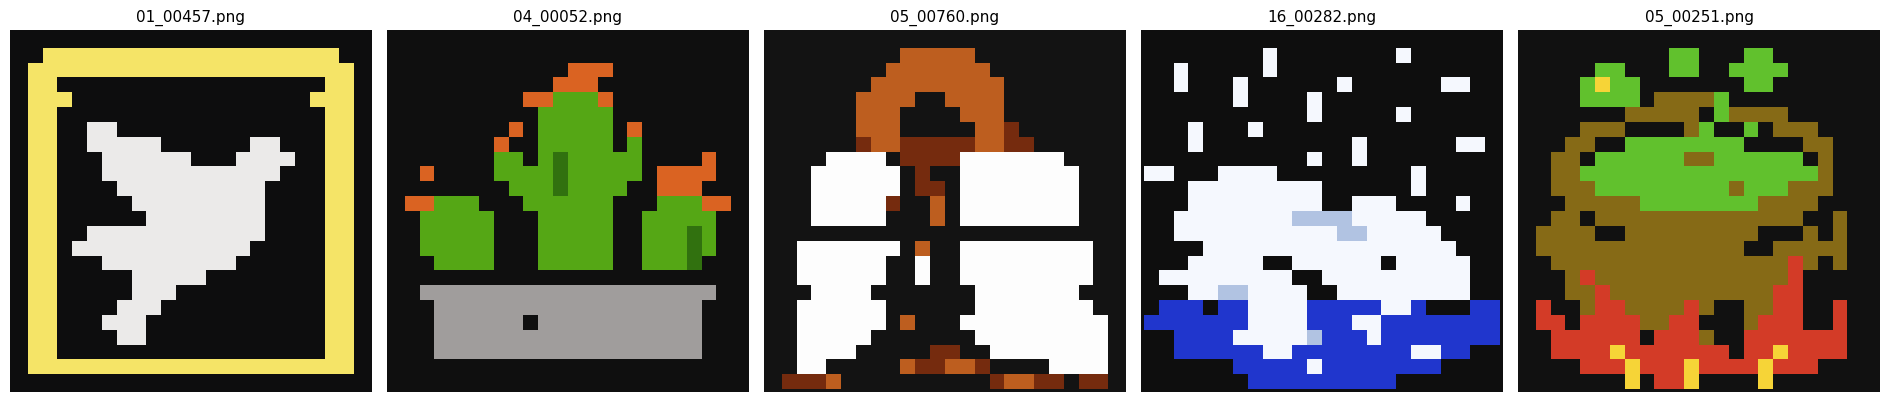

In [ ]:
REFERENCE_FILENAMES = []

rng = random.Random(SEED)
if REFERENCE_FILENAMES:
    lookup = {r["file_name"]: r for r in records}
    reference_rows = [lookup[name] for name in REFERENCE_FILENAMES]
    if len(reference_rows) != 5:
        raise ValueError("REFERENCE_FILENAMES must contain exactly 5 filenames.")
else:
    reference_rows = []
    for family_prefix in ["01", "04", "05", "16", "05"]:
        choices = [r for r in records if r["file_name"].startswith(family_prefix + "_")
                   and isinstance(r.get("text"), str) and r["text"].strip()
                   and r not in reference_rows]
        reference_rows.append(rng.choice(choices))

PROMPTS = ["pixel art of " + r["text"].strip() for r in reference_rows]

for i, (r, prompt) in enumerate(zip(reference_rows, PROMPTS), start=1):
    print(f"{i}. {r['file_name']} | {prompt}")

fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
for ax, row in zip(axes, reference_rows):
    with Image.open(IMAGE_DIR / row["file_name"]) as im:
        ax.imshow(im.convert("RGB"), interpolation="nearest")
    ax.set_title(row["file_name"], fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 6. Load Stable Diffusion 1.5

In [ ]:
from diffusers import StableDiffusionPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DEVICE = "cuda"

print("Loading Stable Diffusion 1.5...")
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True,
)
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=False)
pipe.text_encoder.eval()
pipe.unet.eval()
pipe.vae.eval()

print("Model loaded:", MODEL_ID)
print("Scheduler:", type(pipe.scheduler).__name__)
print("CLIP tokenizer:", type(pipe.tokenizer).__name__)
print("CLIP text encoder:", type(pipe.text_encoder).__name__)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Loading Stable Diffusion 1.5...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

... (11 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Model loaded: stable-diffusion-v1-5/stable-diffusion-v1-5
Scheduler: PNDMScheduler
CLIP tokenizer: CLIPTokenizer
CLIP text encoder: CLIPTextModel


## Task 7. Encode Text with CLIP

In [ ]:
def clip_encode(texts):
    tokenized = pipe.tokenizer(
        texts,
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    )
    token_ids = tokenized.input_ids.to(DEVICE)
    with torch.inference_mode():
        embeddings = pipe.text_encoder(token_ids)[0]
    return tokenized.input_ids, embeddings

token_ids, prompt_embeddings = clip_encode(PROMPTS)
_, negative_embeddings = clip_encode([""] * len(PROMPTS))

print("CLIP token shape:", tuple(token_ids.shape))
print("Text embedding shape:", tuple(prompt_embeddings.shape))
print("Unconditional embedding shape:", tuple(negative_embeddings.shape))
print("Text embedding dtype:", prompt_embeddings.dtype)
print("Example token IDs:", token_ids[0, :12].tolist())

torch.save({
    "model_id": MODEL_ID,
    "prompts": PROMPTS,
    "reference_filenames": [r["file_name"] for r in reference_rows],
    "token_ids": token_ids.cpu(),
    "prompt_embeds": prompt_embeddings.detach().cpu(),
    "negative_prompt_embeds": negative_embeddings.detach().cpu(),
}, RESULT_DIR / "clip_text_embeddings.pt")
print("Saved CLIP embeddings.")

CLIP token shape: (5, 77)
Text embedding shape: (5, 77, 768)
Unconditional embedding shape: (5, 77, 768)
Text embedding dtype: torch.float16
Example token IDs: [49406, 13241, 794, 539, 45016, 3329, 530, 3795, 6481, 49407, 49407, 49407]
Saved CLIP embeddings.


## Task 8. Generate and Compare Images

In [ ]:

INFERENCE_STEPS = 30
GUIDANCE_SCALE = 7.5
GENERATE_SIZE = 512
SKIP_EXISTING = True
MAX_ATTEMPTS = 5

baseline_runs = {}

def generate_and_compare(index):
    row = reference_rows[index]
    prompt = PROMPTS[index]
    number = index + 1

    generated_path = BASELINE_DIR / f"baseline_{number:02d}.png"
    pair_path = BASELINE_DIR / f"comparison_{number:02d}.png"
    config_path = BASELINE_DIR / f"baseline_{number:02d}_config.json"

    current_config = {
        "reference_file": row["file_name"],
        "prompt": prompt,
        "seed": SEED,
        "steps": INFERENCE_STEPS,
        "guidance_scale": GUIDANCE_SCALE,
        "model_id": MODEL_ID,
    }

    cached_config = (
        json.loads(config_path.read_text(encoding="utf-8"))
        if config_path.is_file() else {}
    )

    cache_matches = (
        SKIP_EXISTING
        and generated_path.is_file()
        and all(
            cached_config.get(k) == v
            for k, v in current_config.items()
        )
    )

    if cache_matches:
        with Image.open(generated_path) as im:
            generated = im.convert("RGB").copy()

        if generated.getbbox() is None:
            cache_matches = False

    if cache_matches:
        actual_seed = cached_config.get("actual_seed", SEED)
        duration = None
        print(f"[{number}/5] Reused: {generated_path.name}")

    else:
        print(f"[{number}/5] Generating: {prompt}", flush=True)
        started = time.time()

        for attempt in range(MAX_ATTEMPTS):
            actual_seed = SEED + attempt
            generator = torch.Generator(
                device=DEVICE
            ).manual_seed(actual_seed)

            with torch.inference_mode():
                output = pipe(
                    prompt_embeds=prompt_embeddings[index:index + 1],
                    negative_prompt_embeds=negative_embeddings[index:index + 1],
                    height=GENERATE_SIZE,
                    width=GENERATE_SIZE,
                    num_inference_steps=INFERENCE_STEPS,
                    guidance_scale=GUIDANCE_SCALE,
                    generator=generator,
                )

            generated = output.images[0]

            flagged = any(
                output.nsfw_content_detected or []
            )
            black_image = generated.getbbox() is None

            if not flagged and not black_image:
                break

            print(
                f"Seed {actual_seed}: rejected, retrying...",
                flush=True
            )

        else:
            raise RuntimeError(
                f"Generation failed after {MAX_ATTEMPTS} attempts."
            )

        duration = round(time.time() - started, 2)

        generated.save(generated_path)

        saved_config = {
            **current_config,
            "actual_seed": actual_seed,
        }

        config_path.write_text(
            json.dumps(
                saved_config,
                ensure_ascii=False,
                indent=2
            ),
            encoding="utf-8"
        )

        print(
            f"[{number}/5] Saved: {generated_path.name} "
            f"(seed={actual_seed}, {duration}s)",
            flush=True
        )

    with Image.open(IMAGE_DIR / row["file_name"]) as im:
        reference = im.convert("RGB").copy()

    paired = Image.new("RGB", (1024, 512), "white")
    paired.paste(reference, (0, 0))
    paired.paste(generated, (512, 0))
    paired.save(pair_path)

    baseline_runs[number] = {
        "reference_file": row["file_name"],
        "caption": row["text"],
        "prompt": prompt,
        "generated_file": generated_path.name,
        "comparison_file": pair_path.name,
        "seed": actual_seed,
        "steps": INFERENCE_STEPS,
        "guidance_scale": GUIDANCE_SCALE,
        "seconds_generated": duration,
    }

    with open(
        BASELINE_DIR / "baseline_runs.jsonl",
        "w",
        encoding="utf-8"
    ) as f:
        for k in sorted(baseline_runs):
            f.write(
                json.dumps(
                    baseline_runs[k],
                    ensure_ascii=False
                ) + "\n"
            )

    print(f"Reference (left): {row['file_name']}")
    print(f"Generated (right): {prompt}")
    display(paired)

    return pair_path


[1/5] Reused: baseline_01.png
Reference (left): 01_00457.png
Generated (right): pixel art of cutout bird in flight frame


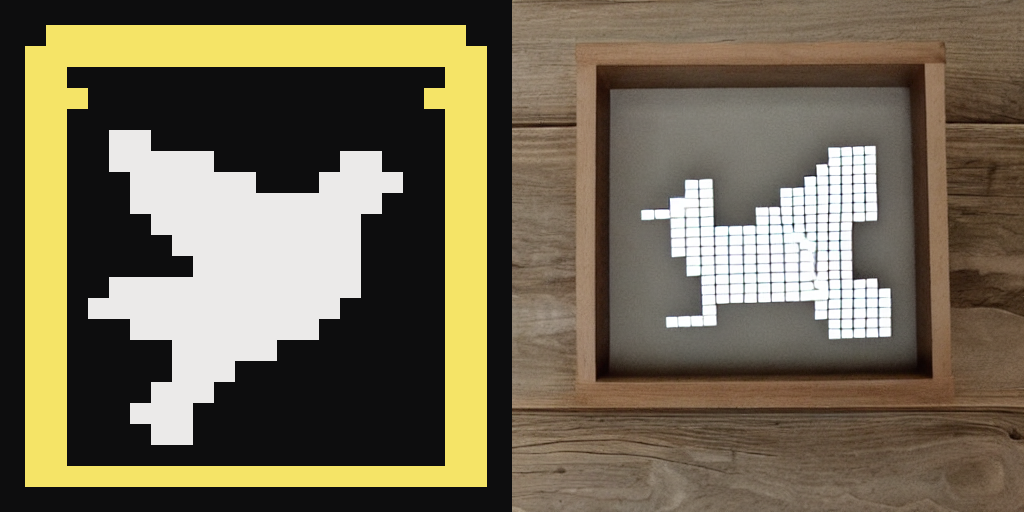

PosixPath('/content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/milestone1_v3_1/baseline/comparison_01.png')

In [ ]:
generate_and_compare(0)

[2/5] Reused: baseline_02.png
Reference (left): 04_00052.png
Generated (right): pixel art of tiny cactus garden with flowers


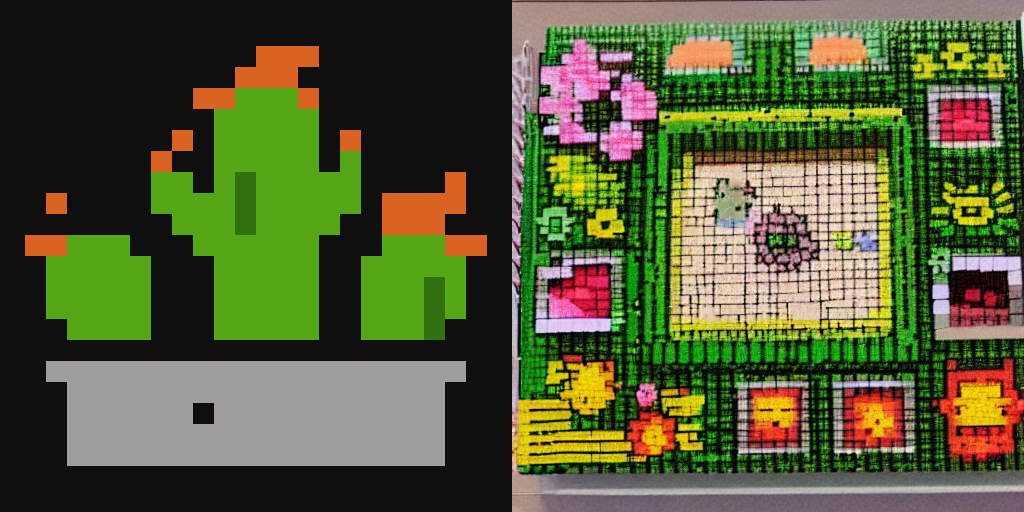

[3/5] Reused: baseline_03.png
Reference (left): 05_00760.png
Generated (right): pixel art of hot fudge cascade


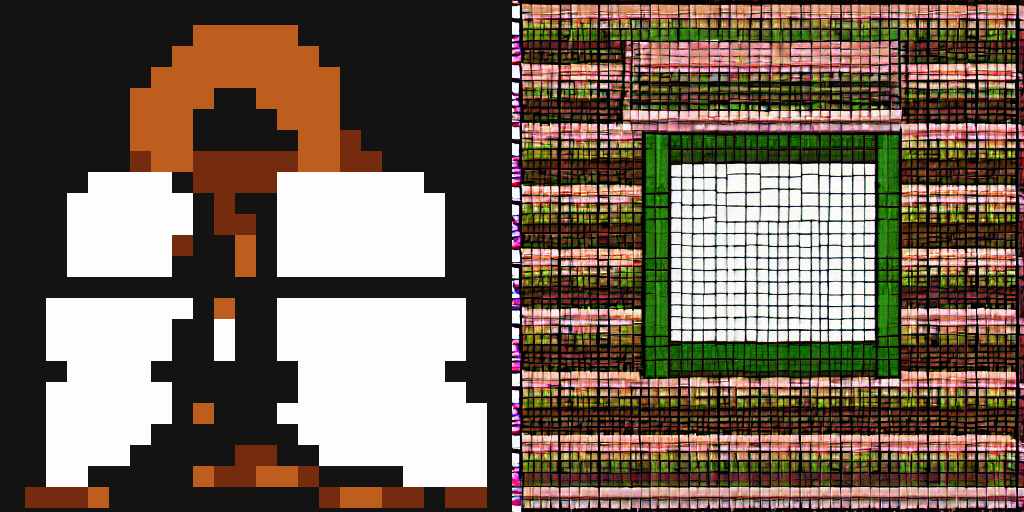

[4/5] Reused: baseline_04.png
Reference (left): 16_00282.png
Generated (right): pixel art of melting snow fleeting


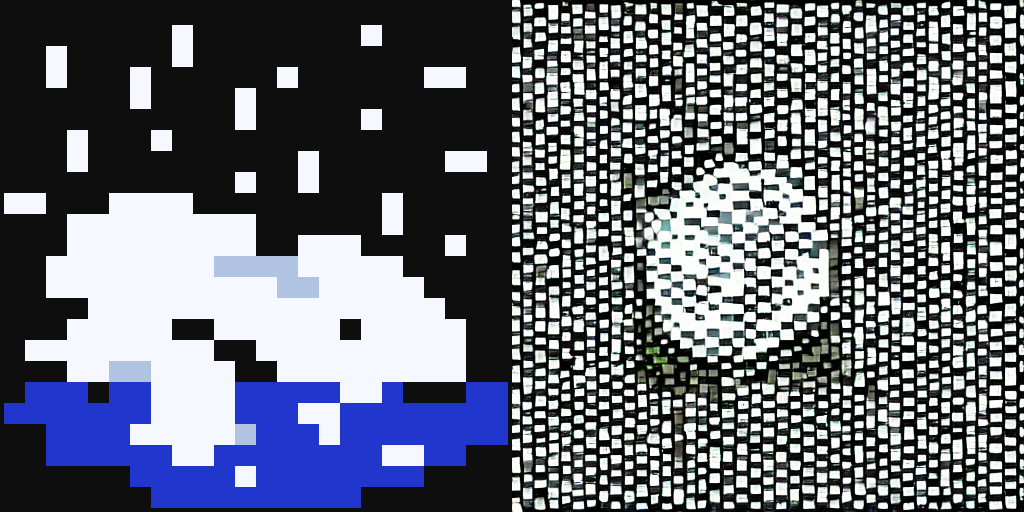

[5/5] Generating: pixel art of Hydras brew


  0%|          | 0/30 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Seed 42: rejected, retrying...


  0%|          | 0/30 [00:00<?, ?it/s]

[5/5] Saved: baseline_05.png (seed=43, 5.72s)
Reference (left): 05_00251.png
Generated (right): pixel art of Hydras brew


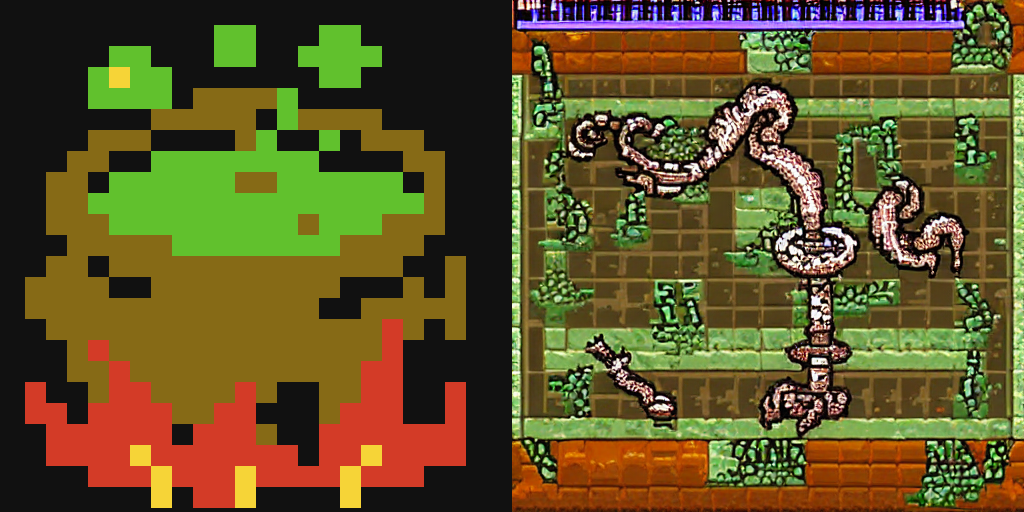

In [ ]:
for index in range(1, 5):
    generate_and_compare(index)

## Task 9. Save Comparison Gallery

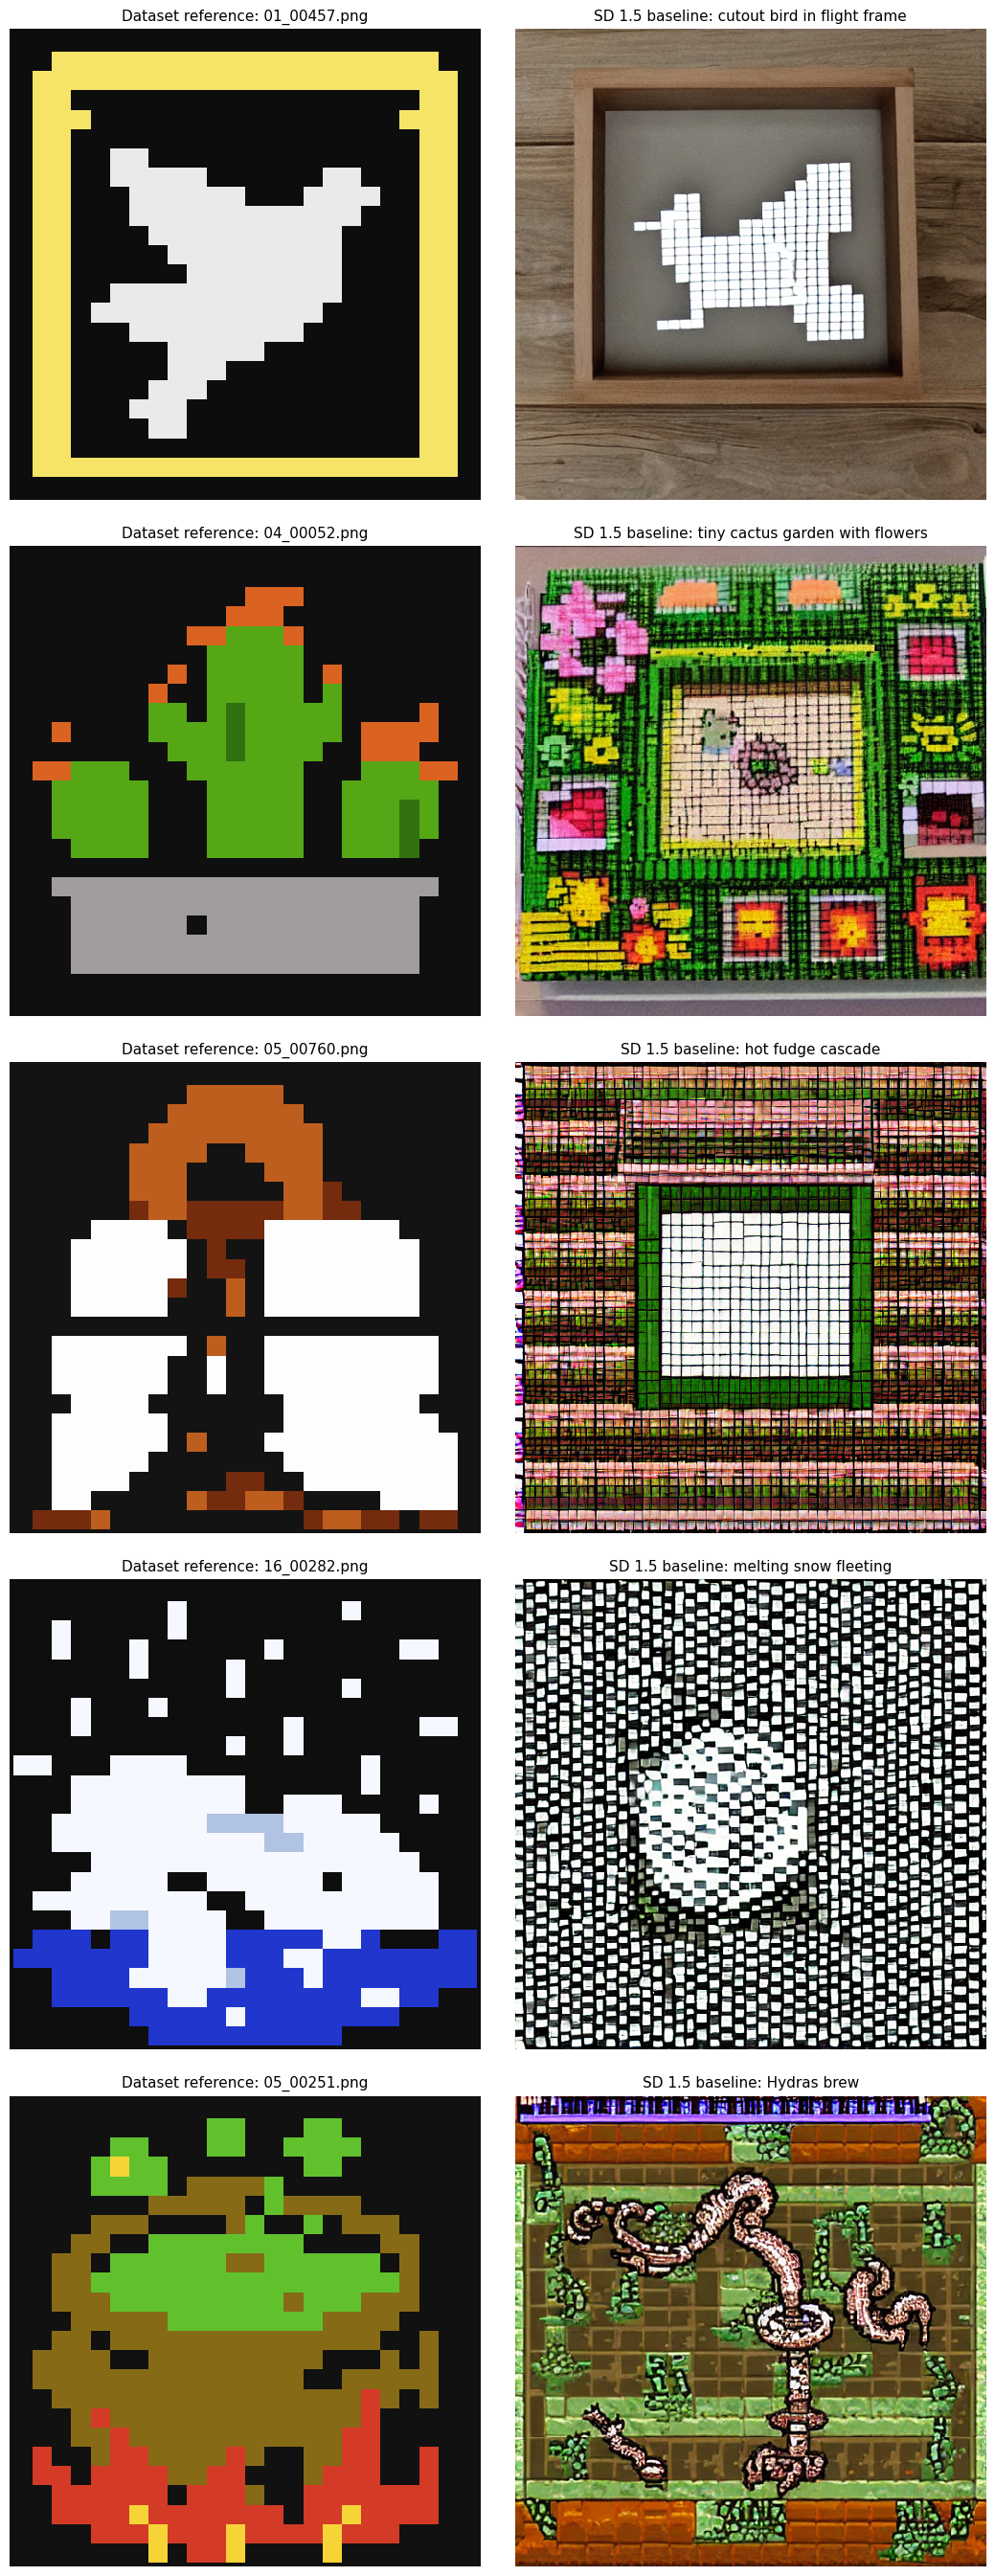

Saved comparison gallery: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/milestone1_v3_1/baseline/comparison_gallery.png

Final dataset pairs (not reduced): 5219
Saved baseline generations: 5
Output directory: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/milestone1_v3_1/baseline


In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(11, 27))
for i, row in enumerate(reference_rows):
    with Image.open(IMAGE_DIR / row["file_name"]) as im:
        axes[i, 0].imshow(im.convert("RGB"), interpolation="nearest")
    with Image.open(BASELINE_DIR / f"baseline_{i + 1:02d}.png") as im:
        axes[i, 1].imshow(im.convert("RGB"), interpolation="nearest")
    axes[i, 0].set_title(f"Dataset reference: {row['file_name']}", fontsize=11)
    axes[i, 1].set_title(f"SD 1.5 baseline: {row['text']}", fontsize=11)
    for a in axes[i]:
        a.axis("off")
fig.tight_layout(h_pad=2)
gallery_path = BASELINE_DIR / "comparison_gallery.png"
fig.savefig(gallery_path, dpi=115, bbox_inches="tight")
plt.show()
print("Saved comparison gallery:", gallery_path)

print("\nFinal dataset pairs (not reduced):", len(records))
print("Saved baseline generations:", sum((BASELINE_DIR / f"baseline_{i:02d}.png").is_file() for i in range(1, 6)))
print("Output directory:", BASELINE_DIR)